# Module 3 · Generating Data
**Verse 3, first half · 1:59–2:07**

Every model so far *predicts* something: a label, a number, the next character. A **generative** model makes new examples that look like its training data: faces, images, sounds. Verse 3 opens with the two ideas that took generation from blurry to photorealistic:

GAN (two networks playing a game) → diffusion (one network learning to remove noise).

Both labs use a toy dataset, 25 blobs on a grid (the film's 25 target modes), so they train in seconds and you can *see* what each method gets right and wrong.



In [1]:
import sys; sys.path.insert(0, '.')
from blcourse import *
import matplotlib.pyplot as plt
hardware_report()



python 3.11.15 · torch 2.15.0 · arm64 · 64 GB RAM
DEVICE = 'mps'   TIER = 'laptop'   (override: BASELINE_TIER / BASELINE_DEVICE)


## 3.1 GANs played a two-player game
A **generative** model learns to produce new samples that look like the training data. Our "data" is 25 Gaussian blobs on a grid, the same 25 targets as the film's GAN court. Each blob is a **mode**, and a good generator should produce all 25.

> **Predict first.** By the end of training, how many of the 25 blobs will the generator produce samples for?

A **GAN** (Goodfellow et al., 2014) trains two networks against each other. The generator G turns random noise into samples. The discriminator D tries to tell real samples from G's. G's loss is D's success, so each one's improvement is the other's new problem.



step     0  modes  1/25  on-target 91%


step   500  modes  0/25  on-target 8%


step  1000  modes  3/25  on-target 12%


step  1500  modes  3/25  on-target 13%


step  2000  modes  5/25  on-target 20%


step  2500  modes  7/25  on-target 35%


step  3000  modes  5/25  on-target 43%


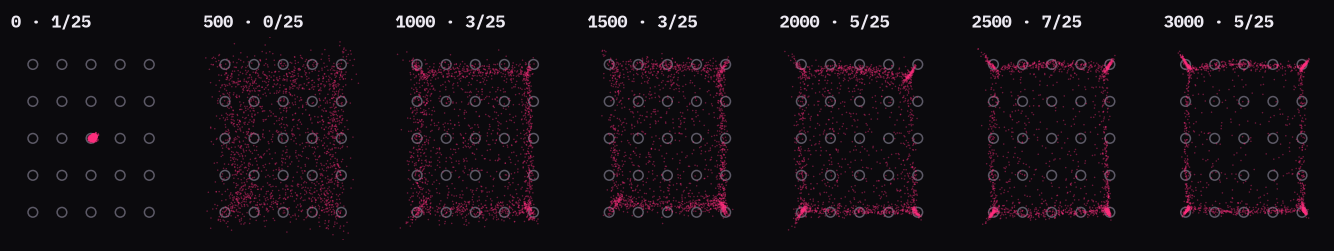

In [2]:
CENTERS = torch.tensor([(x, y) for x in range(-2, 3) for y in range(-2, 3)], dtype=torch.float32) * 2

def real_batch(n):
    return CENTERS[torch.randint(0, 25, (n,))] + 0.05 * torch.randn(n, 2)

def modes_covered(samples, min_frac=0.01):
    d = torch.cdist(samples, CENTERS); near = d.min(1).values < 0.3
    counts = torch.bincount(d.argmin(1)[near], minlength=25)
    return int((counts > min_frac * len(samples)).sum()), near.float().mean().item()

mlp = lambda i, o: nn.Sequential(nn.Linear(i, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, o))
seed(0)
G, D = mlp(8, 2), mlp(2, 1)
oG = torch.optim.Adam(G.parameters(), 1e-3, betas=(0.5, 0.9)); oD = torch.optim.Adam(D.parameters(), 1e-3, betas=(0.5, 0.9))
bce = nn.BCEWithLogitsLoss(); gan_log = []
for step in range(CFG['gan_steps'] + 1):
    real, fake = real_batch(256), G(torch.randn(256, 8))
    lD = bce(D(real), torch.ones(256, 1)) + bce(D(fake.detach()), torch.zeros(256, 1))
    oD.zero_grad(); lD.backward(); oD.step()
    lG = bce(D(fake), torch.ones(256, 1))                 # G wins when D calls its fakes real
    oG.zero_grad(); lG.backward(); oG.step()
    if step % (CFG['gan_steps'] // 6) == 0:
        with torch.no_grad():
            s = G(torch.randn(2000, 8))
        gan_log.append((step, s, *modes_covered(s)))
        print(f'step {step:5d}  modes {gan_log[-1][2]:2d}/25  on-target {gan_log[-1][3]:.0%}')

fig, axes = plt.subplots(1, len(gan_log), figsize=(2.2 * len(gan_log), 2.4))
for ax, (step, s, m, _) in zip(axes, gan_log):
    ax.scatter(*CENTERS.T, s=40, facecolors='none', edgecolors=GRAPHITE)
    ax.scatter(*s.T, s=1, c=MAG, alpha=0.4); ax.set(xlim=(-5.5, 5.5), ylim=(-5.5, 5.5), title=f'{step} · {m}/25'); ax.axis('off')



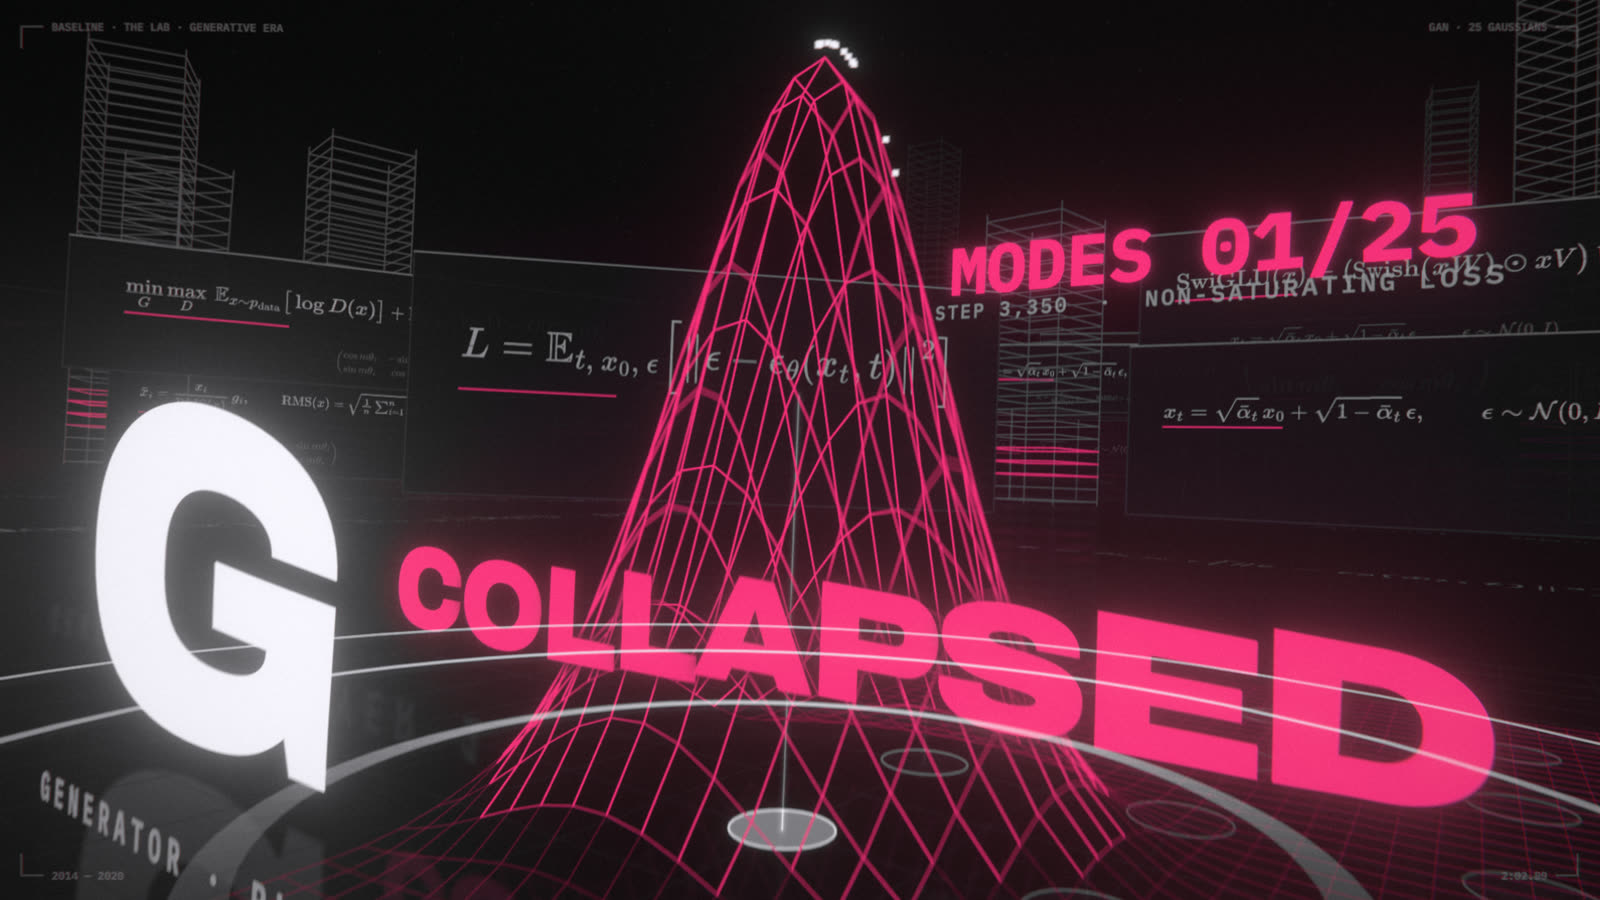

In [3]:
still(122.9)



GANs are notoriously unstable. Rerun with different seeds and you'll see runs that cover most modes, and runs that **collapse** onto a few: the generator finds a handful of outputs that fool D and stops exploring. Hold on to your mode count for the next comparison.



## 3.2 Diffusion learned to denoise in a thousand tiny steps
**Diffusion models** (Sohl-Dickstein 2015; DDPM, Ho et al. 2020) have no adversary. Take a real sample and add a little Gaussian noise, 1,000 times, until it's pure noise. Then train one network on one boring regression task: *given a noisy sample and the step number t, predict the noise that was added*.

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon \qquad L = \lVert \epsilon - \epsilon_\theta(x_t, t)\rVert^2$$

To generate, start from pure noise and subtract the predicted noise one small step at a time. It's a plain regression loss with nothing to collapse, so diffusion tends to cover every mode.

ᾱ ("alpha bar") is just a schedule: a number that starts near 1 (almost no noise) and falls toward 0 (almost all noise) as t goes from 0 to 999. Every x_t is a blend of the clean point and fresh noise, with ᾱ_t setting the mix.

> **Predict first.** The GAN covered a handful of modes. Will diffusion, trained for a similar time, cover more or fewer?



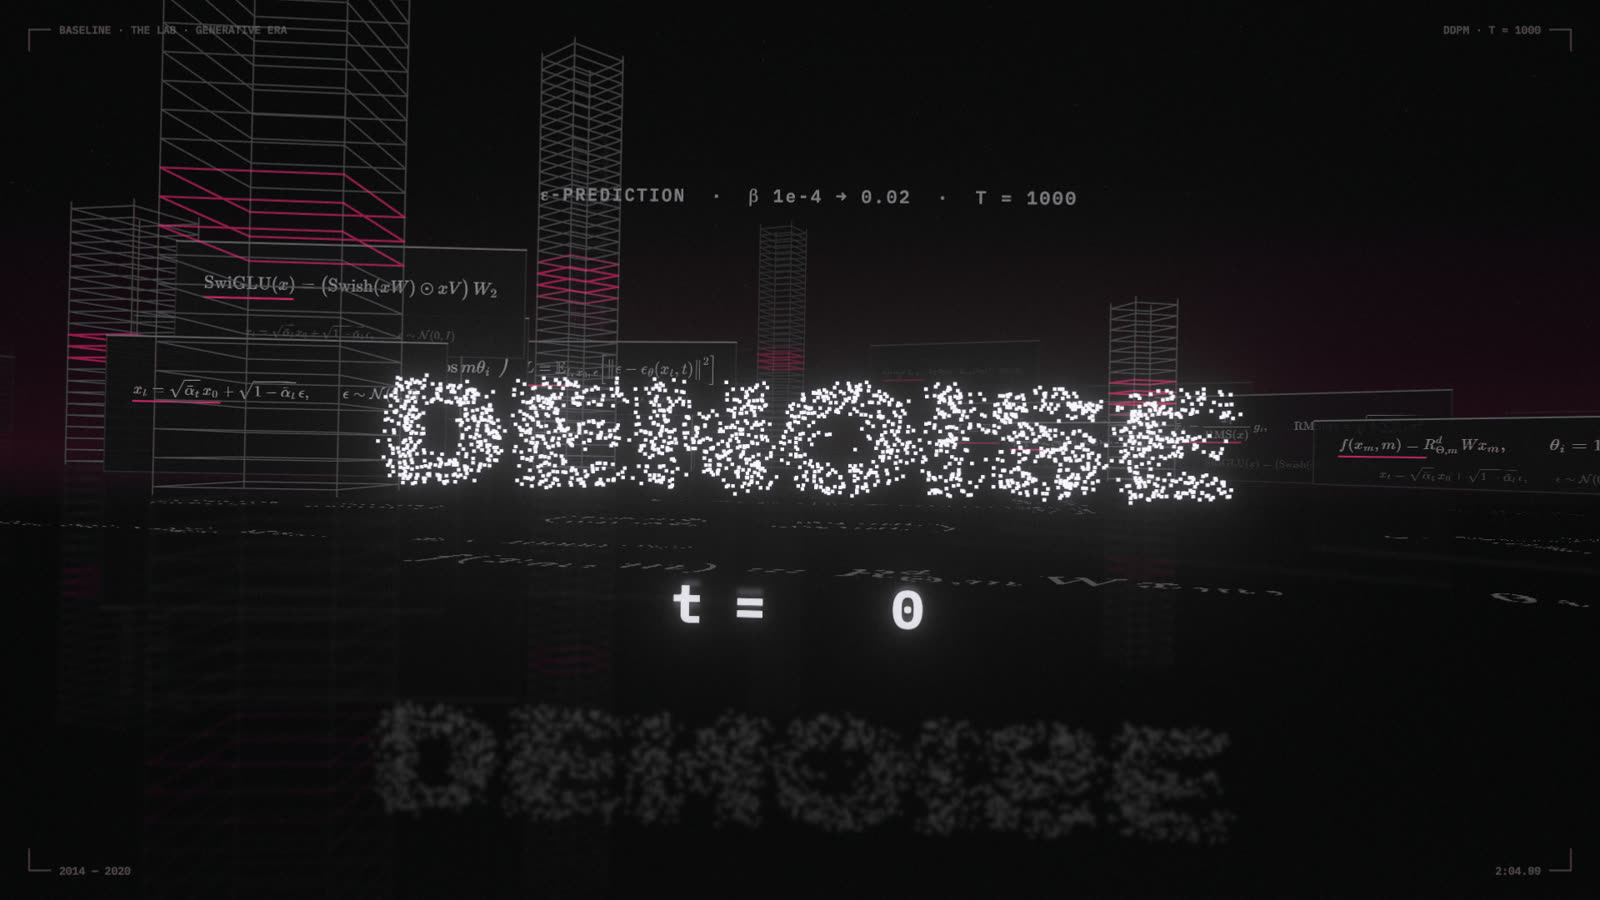

In [4]:
still(124.9)



In [5]:
T = 1000
betas = torch.linspace(1e-4, 0.02, T); abar = torch.cumprod(1 - betas, 0)
print(f'ᾱ at t = 0: {abar[0]:.4f}   t = 300: {abar[300]:.3f}   t = 999: {abar[999]:.5f}')



ᾱ at t = 0: 0.9999   t = 300: 0.394   t = 999: 0.00004


### Your turn: the forward process
Write the noising step: given a clean batch `x0`, a step `t` and noise `eps` (same shape as x0), return x_t from the formula above. The check also confirms that by t = 999 the result is essentially pure noise.



In [6]:
def noisy(x0, t, eps, abar):
    """x0, eps: tensors of the same shape; t: an integer step; abar: the schedule (1000 numbers). Return x_t."""
    raise NotImplementedError        # your code here: one line

check('noisy', noisy)



⏳ noisy: not attempted yet. Fill in the code above and rerun this cell. (Stuck? The reference solution is in notebooks/exercises.py.)


Here is what the network has to learn to undo: the 25 blobs at increasing noise levels.



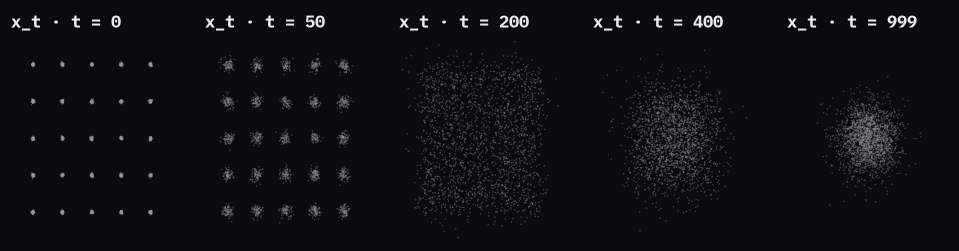

In [7]:
x0, eps = real_batch(2000), torch.randn(2000, 2)
fig, axes = plt.subplots(1, 5, figsize=(11, 2.4))
for ax, t in zip(axes, (0, 50, 200, 400, 999)):
    xt = abar[t].sqrt() * x0 + (1 - abar[t]).sqrt() * eps
    ax.scatter(*xt.T, s=1, c=ASH, alpha=0.4); ax.set(xlim=(-5.5, 5.5), ylim=(-5.5, 5.5), title=f'x_t · t = {t}'); ax.axis('off')



DDPM training: 10.72s


DDPM: modes 25/25   vs   GAN: 5/25


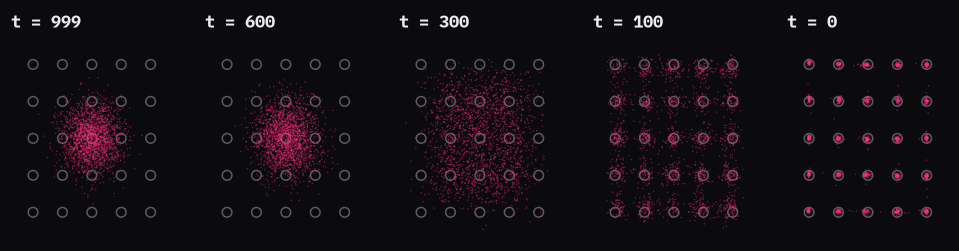

In [8]:

class EpsNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2 + 16, 256), nn.SiLU(), nn.Linear(256, 256), nn.SiLU(), nn.Linear(256, 256), nn.SiLU(), nn.Linear(256, 2))
    def forward(self, x, t):
        f = torch.exp(torch.linspace(0, 6, 8)) * t[:, None] / T           # sinusoidal time embedding
        return self.net(torch.cat([x, f.sin(), f.cos()], 1))

seed(0); eps_net = EpsNet(); opt = torch.optim.Adam(eps_net.parameters(), 1e-3)
with timer('DDPM training:'):
    for step in range(CFG['ddpm_steps']):
        x0 = real_batch(512); t = torch.randint(0, T, (512,)); eps = torch.randn_like(x0)
        xt = abar[t, None].sqrt() * x0 + (1 - abar[t, None]).sqrt() * eps
        loss = F.mse_loss(eps_net(xt, t.float()), eps)
        opt.zero_grad(); loss.backward(); opt.step()

@torch.no_grad()
def ddpm_sample(n, keep=(999, 600, 300, 100, 0)):
    x, frames = torch.randn(n, 2), {}
    for t in reversed(range(T)):
        eps = eps_net(x, torch.full((n,), float(t)))
        x = (x - betas[t] / (1 - abar[t]).sqrt() * eps) / (1 - betas[t]).sqrt()
        if t > 0:
            x += betas[t].sqrt() * torch.randn_like(x)
        if t in keep:
            frames[t] = x.clone()
    return frames

frames = ddpm_sample(2000)
fig, axes = plt.subplots(1, len(frames), figsize=(2.2 * len(frames), 2.4))
for ax, (t, s) in zip(axes, frames.items()):
    ax.scatter(*CENTERS.T, s=40, facecolors='none', edgecolors=GRAPHITE); ax.scatter(*s.T, s=1, c=MAG, alpha=0.4)
    ax.set(xlim=(-5.5, 5.5), ylim=(-5.5, 5.5), title=f't = {t}'); ax.axis('off')
print(f'DDPM: modes {modes_covered(frames[0])[0]}/25   vs   GAN: {gan_log[-1][2]}/25')



The trade-off: a GAN generates in one forward pass, and DDPM needed a thousand. Much of the work since 2020 (DDIM, distillation, flow matching) has gone into cutting that number down.



### Checkpoint
1. In a GAN, what does the discriminator learn, and what does the generator learn?
2. What is mode collapse, and why doesn't diffusion suffer from it?
3. Diffusion's training task is "predict the noise that was added". Why is that easier than "generate an image"?
4. What does a diffusion model trade for its stability?

<details><summary>Answers</summary>

1. The discriminator learns to tell real samples from generated ones. The generator learns to produce samples the discriminator calls real. Each one's progress is the other's new problem.
2. The generator settles on a few outputs that fool the discriminator and stops producing the rest of the data's variety. Diffusion has no opponent to fool: it's a plain regression (predict the noise) over noisy versions of *every* training example, so every mode keeps pulling on the loss.
3. Each step is a small, well-defined correction with a known right answer (the noise you added), so it's ordinary supervised learning. Generating a whole image is never asked of the network directly; it emerges from many small corrections.
4. Speed. A GAN generates in one forward pass; DDPM takes about a thousand. Much later work (DDIM, distillation, flow matching) cuts that number down.
</details>

**Next:** Module 4, a real LLM.